**Name:** Khushi Patel  
**GitHub Username:** khushigi-a11y  
**USC ID:** 4163615025

## Question 1(a): Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, hamming_loss
from sklearn.svm import LinearSVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.multiclass import OneVsRestClassifier
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

# Reproducibility
RANDOM_STATE = 42

In [2]:
# Loading the Anuran Calls (MFCCs) dataset
data_path = "../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7195, 26)


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


In [3]:
# Checking the column names, missing values, and label distributions
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distributions:")
for label in ["Family", "Genus", "Species"]:
    print(f"\n{label}:")
    print(df[label].value_counts())

Columns:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']

Missing values:
MFCCs_ 1    0
MFCCs_ 2    0
MFCCs_ 3    0
MFCCs_ 4    0
MFCCs_ 5    0
MFCCs_ 6    0
MFCCs_ 7    0
MFCCs_ 8    0
MFCCs_ 9    0
MFCCs_10    0
MFCCs_11    0
MFCCs_12    0
MFCCs_13    0
MFCCs_14    0
MFCCs_15    0
MFCCs_16    0
MFCCs_17    0
MFCCs_18    0
MFCCs_19    0
MFCCs_20    0
MFCCs_21    0
MFCCs_22    0
Family      0
Genus       0
Species     0
RecordID    0
dtype: int64

Label distributions:

Family:
Family
Leptodactylidae    4420
Hylidae            2165
Dendrobatidae       542
Bufonidae            68
Name: count, dtype: int64

Genus:
Genus
Adenomera        4150
Hypsiboas        1593
Ameerega          542
Dendropsophus     310
Leptodactylus     270
Scinax

In [4]:
# Separating the features and target labels
X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])
y = df[["Family", "Genus", "Species"]]

# Randomly splitting the data: 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (5036, 22)
Testing features: (2159, 22)
Training labels: (5036, 3)
Testing labels: (2159, 3)


## Question 1(b)i: Exact Match and Hamming Score/Loss
**Exact Match Ratio (Subset Accuracy):** Measures the proportion of observations for which all three labels (Family, Genus, and Species) are predicted correctly. A prediction is considered correct only when every label matches the true labels.

**Hamming Loss:** Measures the amount of incorrectly predicted labels across all observations. Lower values indicate better performance.

**Hamming Score:** Defined here as 1 − Hamming Loss, which shows the fraction of correctly predicted individual labels. Higher values indicate better performance.
These metrics will be used to evaluate the Gaussian SVM, L1-penalized SVM, and SMOTE-enhanced SVM classifiers.

## Question 1(b)ii: Gaussian Kernel SVM

In [5]:
# Evaluating multi-class, multi-label classification performance
def evaluate_model(y_true, y_pred, model_name):
    # Convert DataFrames to NumPy arrays
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Exact match
    exact_match = np.mean(np.all(y_true == y_pred, axis=1))

    # Hamming loss
    loss = np.mean(y_true != y_pred)

    # Hamming score
    score = 1 - loss

    print(f"\n{model_name}")
    print(f"Exact Match Ratio: {exact_match:.4f}")
    print(f"Hamming Loss: {loss:.4f}")
    print(f"Hamming Score: {score:.4f}")

    return {
        "Model": model_name,
        "Exact Match": exact_match,
        "Hamming Loss": loss,
        "Hamming Score": score
    }

In [6]:
# Hyperparameter search space 
param_grid = {
    "classifier__estimator__C": [0.1, 1, 10, 100],
    "classifier__estimator__gamma": [0.01, 0.1, 1, 10]
}

# 10-fold stratified cross-validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_results = []

# Training a separate Gaussian SVM for each label
for label in ["Family", "Genus", "Species"]:
    print(f"\nTraining Gaussian SVM for {label}...")

    # Standardizing features and use One-vs-Rest classification
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(SVC(kernel="rbf")))
    ])

    # Tune C and gamma using cross-validation
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    # Storing the best model and test predictions
    rbf_models[label] = grid.best_estimator_
    rbf_predictions[label] = grid.predict(X_test)

    print("Best parameters:", grid.best_params_)
    print(f"Best CV accuracy: {grid.best_score_:.4f}")

    # Recording the cross-validation and test accuracy
    rbf_results.append({
        "Label": label,
        "Best C": grid.best_params_["classifier__estimator__C"],
        "Best Gamma": grid.best_params_["classifier__estimator__gamma"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], rbf_predictions[label]
        )
    })

rbf_results_df = pd.DataFrame(rbf_results)
display(rbf_results_df)



Training Gaussian SVM for Family...
Best parameters: {'classifier__estimator__C': 10, 'classifier__estimator__gamma': 0.1}
Best CV accuracy: 0.9905

Training Gaussian SVM for Genus...
Best parameters: {'classifier__estimator__C': 10, 'classifier__estimator__gamma': 0.1}
Best CV accuracy: 0.9891

Training Gaussian SVM for Species...
Best parameters: {'classifier__estimator__C': 10, 'classifier__estimator__gamma': 0.1}
Best CV accuracy: 0.9889


,Label,Best C,Best Gamma,CV Accuracy,Test Accuracy
0,Family,10,0.1,0.990468,0.993516
1,Genus,10,0.1,0.989078,0.988421
2,Species,10,0.1,0.988880,0.987957


In [7]:
# Evaluating the predictions across all three labels
rbf_evaluation = evaluate_model(
    y_test,
    rbf_predictions,
    "Gaussian Kernel SVM"
)


Gaussian Kernel SVM
Exact Match Ratio: 0.9866
Hamming Loss: 0.0100
Hamming Score: 0.9900


## Question 1(b)iii: L1-Penalized SVM

In [8]:
# Hyperparameter search space for C
l1_param_grid = {
    "classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_results = []

# Training a separate L1-penalized SVM for each label
for label in ["Family", "Genus", "Species"]:
    print(f"\nTraining L1-Penalized SVM for {label}...")

    # Standardizing the  features and apply One-vs-Rest classification
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=100000,
                tol=1e-3,
                random_state=42
            )
        ))
    ])

    # Finding the optimal C using 10-fold cross-validation
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=l1_param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    # Storing the best model and test predictions
    l1_models[label] = grid.best_estimator_
    l1_predictions[label] = grid.predict(X_test)

    print("Best parameters:", grid.best_params_)
    print(f"Best CV accuracy: {grid.best_score_:.4f}")

    # Recording the cross-validation and test accuracy
    l1_results.append({
        "Label": label,
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], l1_predictions[label]
        )
    })

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)


Training L1-Penalized SVM for Family...
Best parameters: {'classifier__estimator__C': 100}
Best CV accuracy: 0.9408

Training L1-Penalized SVM for Genus...
Best parameters: {'classifier__estimator__C': 100}
Best CV accuracy: 0.9517

Training L1-Penalized SVM for Species...
Best parameters: {'classifier__estimator__C': 10}
Best CV accuracy: 0.9607


,Label,Best C,CV Accuracy,Test Accuracy
0,Family,100,0.940826,0.928208
1,Genus,100,0.951749,0.941640
2,Species,10,0.960682,0.958777


In [9]:
# Evaluating the predictions across all three labels
l1_evaluation = evaluate_model(
    y_test,
    l1_predictions,
    "L1-Penalized SVM"
)


L1-Penalized SVM
Exact Match Ratio: 0.9125
Hamming Loss: 0.0571
Hamming Score: 0.9429


## Question 1(b)iv: L1-Penalized SVM with SMOTE

In [10]:
# Hyperparameter search space for C
smote_param_grid = {
    "classifier__estimator__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_results = []

# Training a separate L1-penalized SVM with SMOTE for each label
for label in ["Family", "Genus", "Species"]:
    print(f"\nTraining L1 SVM with SMOTE for {label}...")

    # Standardizing the features and applying SMOTE to balance classes
    pipeline = ImbPipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42, k_neighbors=5)),
        ("classifier", OneVsRestClassifier(
            LinearSVC(
                penalty="l1",
                dual=False,
                max_iter=100000,
                tol=1e-3,
                random_state=42
            )
        ))
    ])

    # Finding the optimal C using 10-fold cross-validation
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=smote_param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train[label])

    # Storing the best model and test predictions
    smote_models[label] = grid.best_estimator_
    smote_predictions[label] = grid.predict(X_test)

    print("Best parameters:", grid.best_params_)
    print(f"Best CV accuracy: {grid.best_score_:.4f}")

    # Recording the cross-validation and test accuracy
    smote_results.append({
        "Label": label,
        "Best C": grid.best_params_["classifier__estimator__C"],
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": accuracy_score(
            y_test[label], smote_predictions[label]
        )
    })

smote_results_df = pd.DataFrame(smote_results)
display(smote_results_df)


Training L1 SVM with SMOTE for Family...
Best parameters: {'classifier__estimator__C': 100}
Best CV accuracy: 0.9232

Training L1 SVM with SMOTE for Genus...
Best parameters: {'classifier__estimator__C': 10}
Best CV accuracy: 0.9130

Training L1 SVM with SMOTE for Species...
Best parameters: {'classifier__estimator__C': 10}
Best CV accuracy: 0.9585


,Label,Best C,CV Accuracy,Test Accuracy
0,Family,100,0.923156,0.908754
1,Genus,10,0.913036,0.901806
2,Species,10,0.958501,0.957851


In [11]:
# Evaluating predictions across all three labels
smote_evaluation = evaluate_model(
    y_test,
    smote_predictions,
    "L1-Penalized SVM with SMOTE"
)


L1-Penalized SVM with SMOTE
Exact Match Ratio: 0.8532
Hamming Loss: 0.0772
Hamming Score: 0.9228


In [12]:
# Comparing the performance of all three classifiers
comparison_df = pd.DataFrame([
    rbf_evaluation,
    l1_evaluation,
    smote_evaluation
])

display(comparison_df)

,Model,Exact Match,Hamming Loss,Hamming Score
0,Gaussian Kernel SVM,0.986568,0.010036,0.989964
1,L1-Penalized SVM,0.912459,0.057125,0.942875
2,L1-Penalized SVM with SMOTE,0.853173,0.077196,0.922804


### Conclusions — Classifier Comparison

The Gaussian Kernel SVM achieved the best overall performance, with an Exact Match Ratio of 98.66% and a Hamming Loss of 0.0100. This suggests that the nonlinear RBF kernel was more effective at separating the classes than the linear SVM.

The L1-Penalized SVM achieved an Exact Match Ratio of 91.25% and a Hamming Loss of 0.0571, performing worse than the Gaussian SVM.

After applying SMOTE to address class imbalance, the Exact Match Ratio decreased to 85.32%, while Hamming Loss increased to 0.0772. Therefore, SMOTE did not improve overall classification accuracy in this experiment.

However, lower overall accuracy does not necessarily mean SMOTE failed to help minority classes. SMOTE may improve minority-class recall at the expense of majority-class accuracy. Additional class-specific evaluation would be needed to determine whether this occurred.

Overall, the Gaussian Kernel SVM was the best-performing classifier based on Exact Match Ratio and Hamming Loss.

## 2(a): Selecting the Optimal Number of Clusters

In [13]:
# Using the entire dataset, without a train/test split
X_cluster = df.drop(
    columns=["Family", "Genus", "Species", "RecordID"]
)

y_cluster = df[["Family", "Genus", "Species"]].reset_index(drop=True)

# Standardizing the MFCC features
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Clustering features:", X_cluster_scaled.shape)
print("Clustering labels:", y_cluster.shape)

Clustering features: (7195, 22)
Clustering labels: (7195, 3)


In [14]:
# Number of Monte Carlo simulations and possible k values
n_simulations = 50
k_values = range(2, 51)

clustering_results = []
cluster_assignments = {}

# Repeating the K-Means clustering 50 times
for run in range(n_simulations):
    best_k = None
    best_ch = -np.inf
    best_clusters = None

    # Finding the optimal k using the Calinski-Harabasz score
    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=run,
            n_init=10
        )

        clusters = model.fit_predict(X_cluster_scaled)

        ch_score = calinski_harabasz_score(
            X_cluster_scaled, clusters
        )

        if ch_score > best_ch:
            best_ch = ch_score
            best_k = k
            best_clusters = clusters

    # Storing the best k and CH score for each simulation
    clustering_results.append({
        "Run": run + 1,
        "Best k": best_k,
        "CH Score": best_ch
    })

    # Saving the cluster assignments for later evaluation
    cluster_assignments[run] = best_clusters.copy()

    print(f"Run {run + 1}/50 | Best k = {best_k}")

clustering_df = pd.DataFrame(clustering_results)

# Displaying the frequency of optimal k values and average CH score
print("Optimal k frequency:")
print(clustering_df["Best k"].value_counts())

print("\nAverage CH Score:")
print(clustering_df["CH Score"].mean())


Run 1/50 | Best k = 2
Run 2/50 | Best k = 2
Run 3/50 | Best k = 2
Run 4/50 | Best k = 2
Run 5/50 | Best k = 2
Run 6/50 | Best k = 2
Run 7/50 | Best k = 2
Run 8/50 | Best k = 2
Run 9/50 | Best k = 2
Run 10/50 | Best k = 2
Run 11/50 | Best k = 2
Run 12/50 | Best k = 2
Run 13/50 | Best k = 2
Run 14/50 | Best k = 2
Run 15/50 | Best k = 2
Run 16/50 | Best k = 2
Run 17/50 | Best k = 2
Run 18/50 | Best k = 2
Run 19/50 | Best k = 2
Run 20/50 | Best k = 2
Run 21/50 | Best k = 2
Run 22/50 | Best k = 2
Run 23/50 | Best k = 2
Run 24/50 | Best k = 2
Run 25/50 | Best k = 2
Run 26/50 | Best k = 2
Run 27/50 | Best k = 2
Run 28/50 | Best k = 2
Run 29/50 | Best k = 2
Run 30/50 | Best k = 2
Run 31/50 | Best k = 2
Run 32/50 | Best k = 2
Run 33/50 | Best k = 2
Run 34/50 | Best k = 2
Run 35/50 | Best k = 2
Run 36/50 | Best k = 2
Run 37/50 | Best k = 2
Run 38/50 | Best k = 2
Run 39/50 | Best k = 2
Run 40/50 | Best k = 2
Run 41/50 | Best k = 2
Run 42/50 | Best k = 2
Run 43/50 | Best k = 2
Run 44/50 | Best k =

## 2(b): Majority Labels for Each Cluster

In [15]:
# Storing the  majority labels and predicted labels for each simulation
cluster_majorities = {}
cluster_predictions = {}

true_labels = y_cluster.to_numpy()

# Finding the majority labels for each cluster across all simulations
for run in range(n_simulations):
    clusters = cluster_assignments[run]

    majority_labels = {}
    predicted_labels = np.empty_like(true_labels)

    for cluster_id in np.unique(clusters):
        mask = clusters == cluster_id
        cluster_data = y_cluster.loc[mask]

        # Determining the most frequent Family, Genus, and Species
        majority_triplet = [
            cluster_data[label].mode().iloc[0]
            for label in ["Family", "Genus", "Species"]
        ]

        # Assigning majority labels to all observations in the cluster
        majority_labels[cluster_id] = majority_triplet
        predicted_labels[mask] = majority_triplet

    cluster_majorities[run] = majority_labels
    cluster_predictions[run] = predicted_labels

# Displaying the majority labels for the first simulation
majority_df = pd.DataFrame.from_dict(
    cluster_majorities[0],
    orient="index",
    columns=["Family", "Genus", "Species"]
)

majority_df.index.name = "Cluster"
display(majority_df)

,Family,Genus,Species
Cluster,,,
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae


## 2(c): Hamming Distance, Hamming Score, and Hamming Loss

In [16]:
mc_results = []

for run in range(n_simulations):
    predicted_labels = cluster_predictions[run]

    # Comparing the  true and predicted labels
    mismatches = true_labels != predicted_labels

    # Average number of incorrect labels per observation
    hamming_distance = np.mean(
        np.sum(mismatches, axis=1)
    )

    # Hamming loss
    hamming_loss_value = np.mean(mismatches)

    # Hamming score
    hamming_score_value = 1 - hamming_loss_value

    mc_results.append({
        "Run": run + 1,
        "Best k": clustering_results[run]["Best k"],
        "Hamming Distance": hamming_distance,
        "Hamming Loss": hamming_loss_value,
        "Hamming Score": hamming_score_value
    })
    
mc_results_df = pd.DataFrame(mc_results)

print("Number of simulations:", len(mc_results_df))

Number of simulations: 50


In [17]:
summary_df = mc_results_df[
    ["Hamming Distance", "Hamming Loss", "Hamming Score"]
].agg(["mean", "std"])

display(summary_df)

,Hamming Distance,Hamming Loss,Hamming Score
mean,8.940931e-01,2.980310e-01,7.019690e-01
std,1.121495e-16,5.607473e-17,1.121495e-16


### 3(a): Complete Linkage Dendrogram

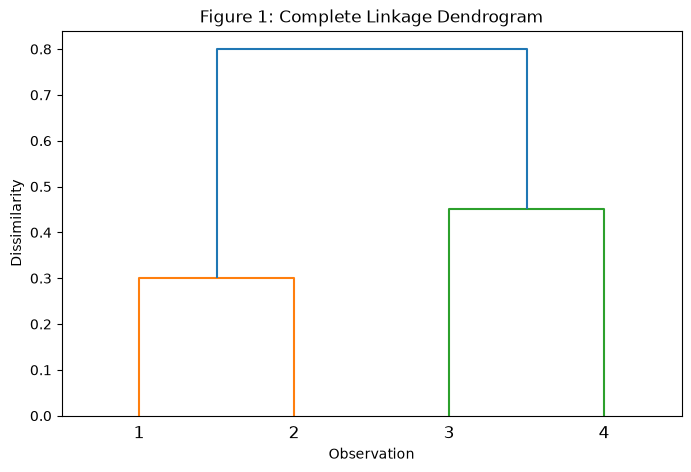

Complete linkage fusion heights:
[0.3  0.45 0.8 ]


In [18]:
# Dissimilarity matrix
D = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

# Converting to condensed distance matrix
distances = squareform(D)

# Completing the linkage
Z_complete = linkage(distances, method="complete")

plt.figure(figsize=(8, 5))
dendrogram(
    Z_complete,
    labels=["1", "2", "3", "4"]
)
plt.title("Figure 1: Complete Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.show()

print("Complete linkage fusion heights:")
print(Z_complete[:, 2])

### 3(b): Single Linkage Dendrogram

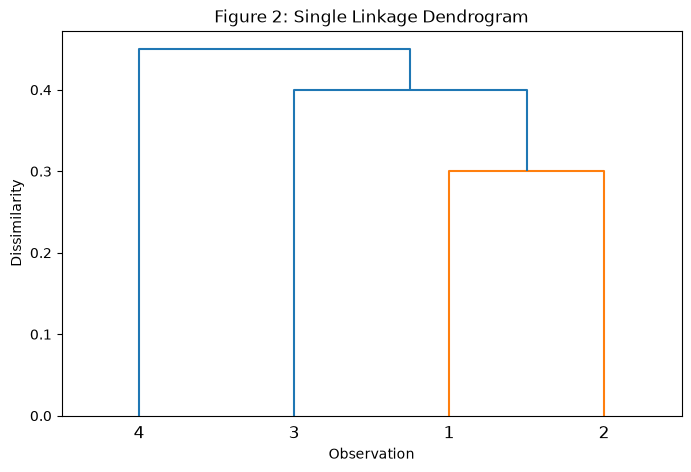

Single linkage fusion heights:
[0.3  0.4  0.45]


In [19]:
# Single linkage
Z_single = linkage(distances, method="single")

plt.figure(figsize=(8, 5))
dendrogram(
    Z_single,
    labels=["1", "2", "3", "4"]
)
plt.title("Figure 2: Single Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.show()

print("Single linkage fusion heights:")
print(Z_single[:, 2])

### 3(c): Two Clusters Using Complete Linkage

Cutting the complete linkage dendrogram to obtain two clusters gives:

- Cluster 1: Observations 1 and 2
- Cluster 2: Observations 3 and 4

### 3(d): Two Clusters Using Single Linkage

Cutting the single linkage dendrogram to obtain two clusters gives:

- Cluster 1: Observations 1, 2, and 3
- Cluster 2: Observation 4

### 3(e): Equivalent Complete Linkage Dendrogram

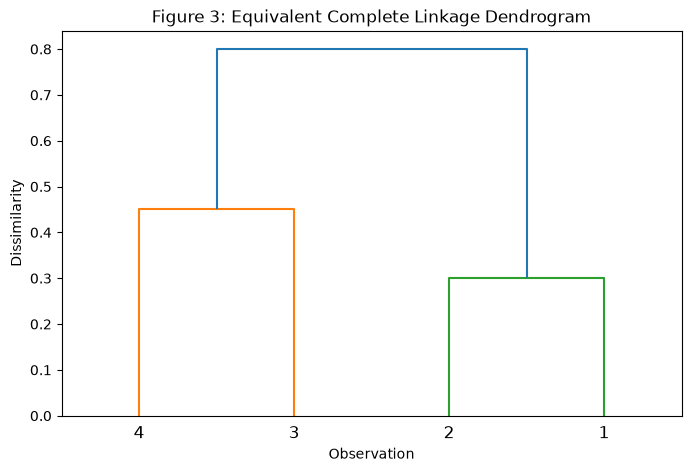

In [20]:
# Swaping the left and right children at each fusion
Z_equivalent = Z_complete.copy()
Z_equivalent[:, [0, 1]] = Z_equivalent[:, [1, 0]]

plt.figure(figsize=(8, 5))
dendrogram(
    Z_equivalent,
    labels=["1", "2", "3", "4"]
)

plt.title("Figure 3: Equivalent Complete Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Dissimilarity")
plt.show()